In [1]:
import torch

print("MomentMind AI setup started!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now.")


MomentMind AI setup started!
PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:

%pip install -q transformers opencv-python-headless gradio


In [3]:

import torch
import cv2
import gradio as gr
import transformers

print("All libraries imported successfully!")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)
print("GPU ready:", torch.cuda.is_available())


All libraries imported successfully!
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
OpenCV: 4.14.0
Gradio: 6.29.0
GPU ready: True


In [4]:

import torch
from transformers import CLIPModel, CLIPProcessor

# Select the pretrained CLIP model
model_name = "openai/clip-vit-base-patch32"

# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Loading pretrained CLIP model...")
print("Selected device:", device)

# Load the model and its processor
processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name)

# Move the model to the selected device
model = model.to(device)

# Set inference mode (no training)
model.eval()

print("CLIP loaded successfully!")
print("Device:", next(model.parameters()).device)


Loading pretrained CLIP model...
Selected device: cuda


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!
Device: cuda:0


In [5]:

from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Uploaded video:", video_path)


Saving 8747616-uhd_2160_3840_25fps.mp4 to 8747616-uhd_2160_3840_25fps.mp4
Uploaded video: 8747616-uhd_2160_3840_25fps.mp4


In [6]:

import cv2
import os

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Video open nahi ho rahi. Please upload another video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("File:", os.path.basename(video_path))
print("FPS:", fps)
print("Total frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()


File: 8747616-uhd_2160_3840_25fps.mp4
FPS: 25.0
Total frames: 249
Resolution: 2160 x 3840
Duration: 9.96 seconds


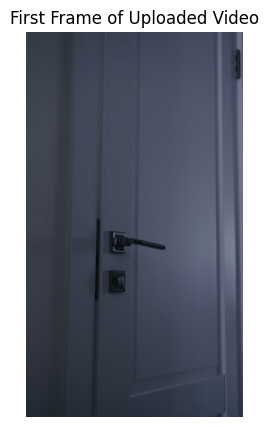

In [7]:

import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
success, frame = cap.read()
cap.release()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 5))
    plt.imshow(frame_rgb)
    plt.title("First Frame of Uploaded Video")
    plt.axis("off")
    plt.show()
else:
    print("Could not read the first frame.")


In [8]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image

cap = cv2.VideoCapture(video_path)

sample_interval = 0.5

frames = []
timestamps = []
blur_scores = []

t = 0.0

while t < duration:
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    success, frame = cap.read()

    if success:
        # Calculate blur score
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blur_score = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        # Convert frame into RGB format
        frame_rgb = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        # Save frame, timestamp, and blur score
        frames.append(Image.fromarray(frame_rgb))
        timestamps.append(round(t, 2))
        blur_scores.append(blur_score)

    t += sample_interval

cap.release()

print("Frames extracted:", len(frames))
print("Timestamps saved:", len(timestamps))
print("Blur scores calculated:", len(blur_scores))

Frames extracted: 20
Timestamps saved: 20
Blur scores calculated: 20


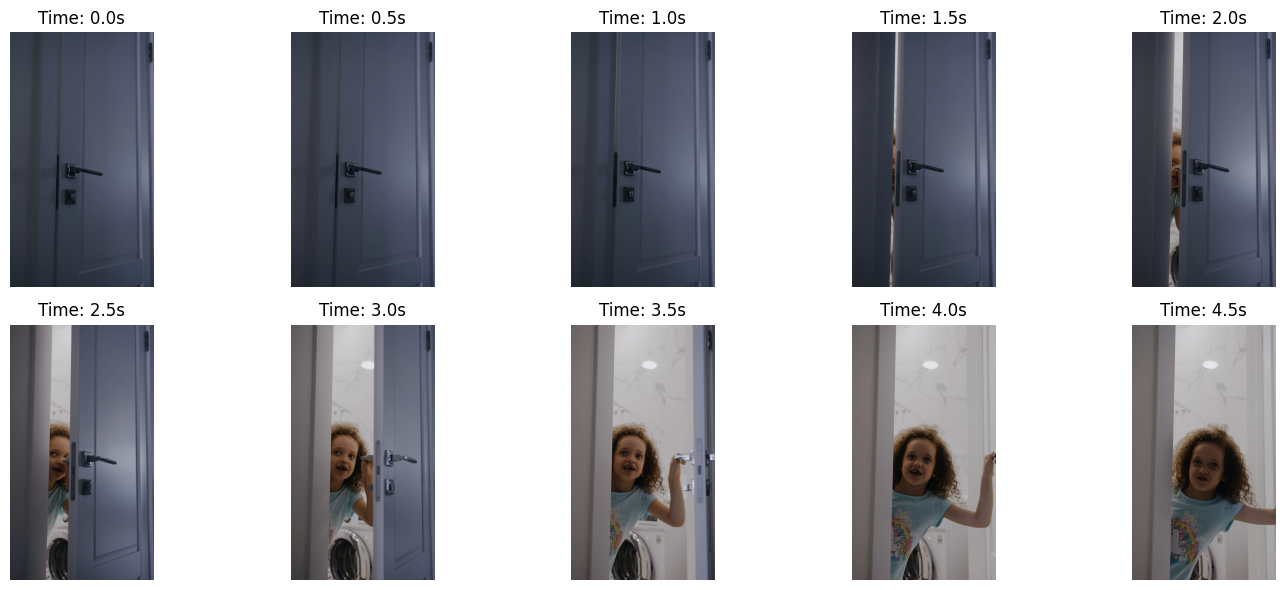

In [9]:
plt.figure(figsize=(15, 6))

for i in range(min(10, len(frames))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(frames[i])
    plt.title(f"Time: {timestamps[i]}s")
    plt.axis("off")

plt.tight_layout()
plt.show()

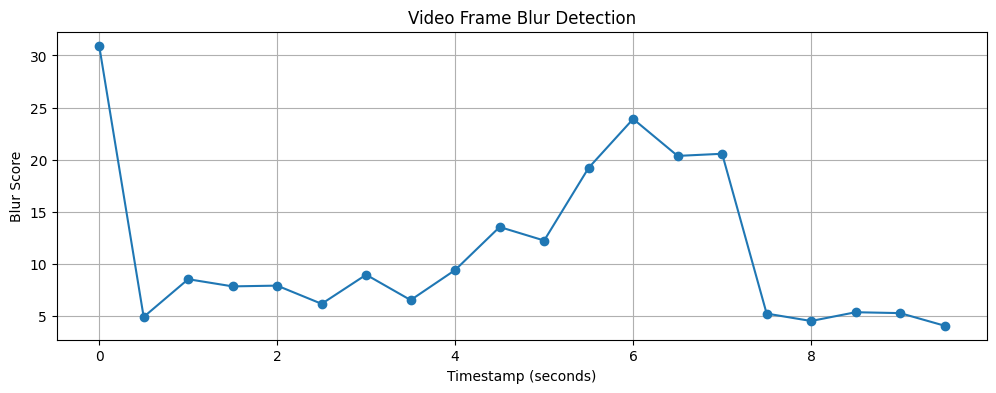

Lowest blur score: 4.1
Highest blur score: 30.94


In [10]:
plt.figure(figsize=(12, 4))

plt.plot(timestamps, blur_scores, marker="o")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Blur Score")
plt.title("Video Frame Blur Detection")
plt.grid(True)

plt.show()

print("Lowest blur score:", round(min(blur_scores), 2))
print("Highest blur score:", round(max(blur_scores), 2))

In [11]:
import torch

def find_moment(query, top_k=5):
    query = query.strip()

    if not query:
        print("Please enter a search query.")
        return

    if len(frames) == 0:
        print("No frames available.")
        return

    # Create different text descriptions for better matching
    prompts = [
        query,
        f"A video frame showing {query}",
        f"The scene where {query}"
    ]

    # Prepare text and image inputs for CLIP
    inputs = processor(
        text=prompts,
        images=frames,
        return_tensors="pt",
        padding=True
    ).to(device)

    # Calculate similarity scores
    with torch.no_grad():
        outputs = model(**inputs)

    # One averaged score for each video frame
    scores = outputs.logits_per_image.mean(dim=1).cpu()

    # Select the top matching frames
    k = min(top_k, len(frames))
    top_indices = torch.argsort(scores, descending=True)[:k]

    print(f"Search query: {query}")
    print(f"Top {k} matching frames:\n")

    for rank, idx in enumerate(top_indices.tolist(), start=1):
        print(
            f"Rank {rank} | "
            f"Timestamp: {timestamps[idx]:.2f}s | "
            f"Similarity score: {scores[idx].item():.3f} | "
            f"Blur score: {blur_scores[idx]:.2f}"
        )

    return [
        {
            "rank": rank,
            "timestamp": timestamps[idx],
            "similarity": round(scores[idx].item(), 3),
            "blur_score": round(blur_scores[idx], 2),
            "image": frames[idx]
        }
        for rank, idx in enumerate(top_indices.tolist(), start=1)
    ]

In [12]:
results = find_moment(
    "the girl is opening a door",
    top_k=5
)

Search query: the girl is opening a door
Top 5 matching frames:

Rank 1 | Timestamp: 9.50s | Similarity score: 31.804 | Blur score: 4.10
Rank 2 | Timestamp: 3.00s | Similarity score: 30.479 | Blur score: 8.98
Rank 3 | Timestamp: 2.00s | Similarity score: 30.479 | Blur score: 7.94
Rank 4 | Timestamp: 1.50s | Similarity score: 30.377 | Blur score: 7.87
Rank 5 | Timestamp: 2.50s | Similarity score: 30.076 | Blur score: 6.19


In [13]:
import matplotlib.pyplot as plt
import math

def display_results(results):
    if not results:
        print("No results to display.")
        return

    n = len(results)
    cols = min(3, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(15, 5 * rows))

    for i, result in enumerate(results):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(result["image"])

        plt.title(
            f'Rank {result["rank"]}\n'
            f'Time: {result["timestamp"]:.2f}s\n'
            f'Similarity: {result["similarity"]:.3f}'
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

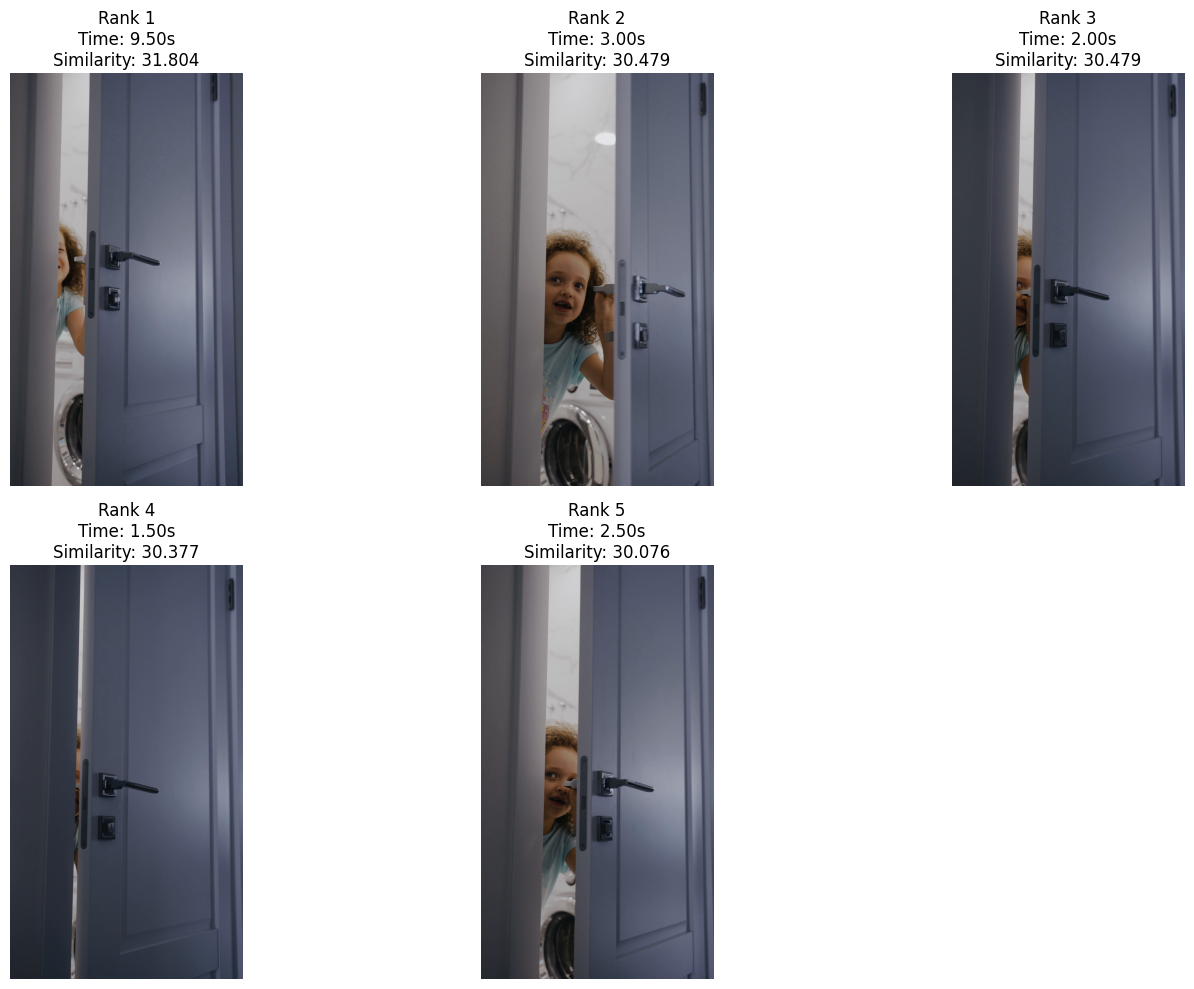

In [14]:
display_results(results)

In [15]:
def estimate_time_window(results, margin=0.5):
    if not results:
        print("No matching results available.")
        return

    best = results[0]
    best_time = best["timestamp"]

    start_time = max(0.0, best_time - margin)
    end_time = min(duration, best_time + margin)

    print("Best matching timestamp:", f"{best_time:.2f}s")
    print("Estimated start time:", f"{start_time:.2f}s")
    print("Estimated end time:", f"{end_time:.2f}s")
    print("Note: These are estimates, not exact action boundaries.")

In [16]:
estimate_time_window(results)

Best matching timestamp: 9.50s
Estimated start time: 9.00s
Estimated end time: 9.96s
Note: These are estimates, not exact action boundaries.


In [18]:
import gradio as gr
import cv2
import os
import math
from PIL import Image
import torch

def process_uploaded_video(video_file, query):
    if video_file is None:
        return [], "Please upload a video first."

    if not query or not query.strip():
        return [], "Please enter an action to search."

    cap = cv2.VideoCapture(video_file)

    if not cap.isOpened():
        return [], "Could not open this video. Try another file."

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    video_duration = total_frames / fps if fps > 0 else 0

    if video_duration <= 0:
        cap.release()
        return [], "Could not determine the video duration."

    sample_interval = 0.5
    video_frames = []
    video_timestamps = []
    video_blur_scores = []

    t = 0.0

    while t < video_duration:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        success, frame = cap.read()

        if success:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            blur_score = cv2.Laplacian(
                gray, cv2.CV_64F
            ).var()

            frame_rgb = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            video_frames.append(Image.fromarray(frame_rgb))
            video_timestamps.append(round(t, 2))
            video_blur_scores.append(blur_score)

        t += sample_interval

    cap.release()

    if not video_frames:
        return [], "No readable frames were found in this video."

    prompts = [
        query.strip(),
        f"A video frame showing {query.strip()}",
        f"The scene where {query.strip()}"
    ]

    inputs = processor(
        text=prompts,
        images=video_frames,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.mean(dim=1).cpu()

    k = min(5, len(video_frames))
    top_indices = torch.argsort(
        scores, descending=True
    )[:k].tolist()

    gallery = []

    for rank, idx in enumerate(top_indices, start=1):
        caption = (
            f"Rank {rank} | "
            f"Time: {video_timestamps[idx]:.2f}s | "
            f"Similarity: {scores[idx].item():.3f} | "
            f"Blur score: {video_blur_scores[idx]:.2f}"
        )

        gallery.append((video_frames[idx], caption))

    best_idx = top_indices[0]
    best_time = video_timestamps[best_idx]

    start_time = max(0.0, best_time - sample_interval)
    end_time = min(
        video_duration, best_time + sample_interval
    )

    low_clarity_count = sum(
        score < 30 for score in video_blur_scores
    )
    low_clarity_percent = (
        100 * low_clarity_count / len(video_blur_scores)
    )

    report = (
        f"Video: {os.path.basename(video_file)}\n"
        f"Duration: {video_duration:.2f} seconds\n"
        f"Frames analyzed: {len(video_frames)}\n"
        f"Search query: {query}\n\n"
        f"Best matching timestamp: {best_time:.2f}s\n"
        f"Estimated start: {start_time:.2f}s\n"
        f"Estimated end: {end_time:.2f}s\n\n"
        f"Frames with blur score below 30: "
        f"{low_clarity_percent:.1f}%\n\n"
        "Note: Similarity scores rank the frames; they are not "
        "probabilities. The time window is approximate. "
        "The blur threshold is a rough warning, not a universal "
        "definition of blur."
    )

    return gallery, report


demo = gr.Interface(
    fn=process_uploaded_video,
    inputs=[
        gr.Video(label="Upload a video"),
        gr.Textbox(
            label="Describe the action",
            placeholder="e.g. A person opens a door"
        )
    ],
    outputs=[
        gr.Gallery(label="Top 5 Matching Frames", columns=3),
        gr.Textbox(label="Search Report", lines=10)
    ],
    title="MomentMind AI",
    description=(
        "Upload a video and search for an action using natural language."
    ),
    flagging_mode="never"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d479833c0b31635879.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
%pip install -q flask

In [20]:
import flask
import cv2
import torch
import transformers

print("Flask version:", flask.__version__)
print("OpenCV version:", cv2.__version__)
print("PyTorch version:", torch.__version__)
print("CLIP model ready:", model is not None)
print("Device:", device)

Flask version: 3.1.3
OpenCV version: 4.14.0
PyTorch version: 2.11.0+cu130
CLIP model ready: True
Device: cuda


/tmp/ipykernel_1842/809124468.py:6: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask version:", flask.__version__)


In [21]:
import os

project_dir = "/content/MomentMind_AI"

folders = [
    "templates",
    "static",
    "uploads",
    "outputs"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

print("Project folder created successfully!")
print("Location:", project_dir)

for folder in folders:
    print("-", folder)

Project folder created successfully!
Location: /content/MomentMind_AI
- templates
- static
- uploads
- outputs


In [22]:
%%writefile /content/MomentMind_AI/app.py

import os
import cv2
import torch
import numpy as np

from flask import Flask, render_template, request
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from werkzeug.utils import secure_filename

app = Flask(__name__)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
UPLOAD_FOLDER = os.path.join(BASE_DIR, "uploads")
OUTPUT_FOLDER = os.path.join(BASE_DIR, "outputs")

os.makedirs(UPLOAD_FOLDER, exist_ok=True)
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

app.config["MAX_CONTENT_LENGTH"] = 200 * 1024 * 1024

ALLOWED_EXTENSIONS = {"mp4", "mov", "avi", "mkv"}

device = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "openai/clip-vit-base-patch32"

print("Loading CLIP model...")

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

print("CLIP model loaded on:", device)


def allowed_file(filename):
    return (
        "." in filename
        and filename.rsplit(".", 1)[1].lower()
        in ALLOWED_EXTENSIONS
    )


def search_video(video_path, query):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return [], "Could not open this video."

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = total_frames / fps if fps > 0 else 0

    if duration <= 0:
        cap.release()
        return [], "Could not determine the video duration."

    frames = []
    timestamps = []
    blur_scores = []

    interval = 0.5
    t = 0.0

    while t < duration:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        success, frame = cap.read()

        if success:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            blur = cv2.Laplacian(gray, cv2.CV_64F).var()

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            frames.append(Image.fromarray(rgb))
            timestamps.append(round(t, 2))
            blur_scores.append(float(blur))

        t += interval

    cap.release()

    if not frames:
        return [], "No readable frames were found."

    prompts = [
        query.strip(),
        f"A video frame showing {query.strip()}",
        f"The scene where {query.strip()}"
    ]

    inputs = processor(
        text=prompts,
        images=frames,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.mean(dim=1).cpu()

    top_indices = torch.argsort(
        scores, descending=True
    )[:min(5, len(frames))].tolist()

    results = []

    for rank, idx in enumerate(top_indices, start=1):
        filename = f"frame_{rank}_{idx}.jpg"
        output_path = os.path.join(OUTPUT_FOLDER, filename)

        frames[idx].save(output_path, format="JPEG")

        results.append({
            "rank": rank,
            "timestamp": timestamps[idx],
            "similarity": round(scores[idx].item(), 3),
            "blur_score": round(blur_scores[idx], 2),
            "image": filename
        })

    best_time = timestamps[top_indices[0]]

    report = {
        "duration": round(duration, 2),
        "frames_analyzed": len(frames),
        "best_time": best_time,
        "start_time": round(max(0, best_time - interval), 2),
        "end_time": round(min(duration, best_time + interval), 2),
        "low_clarity_percent": round(
            100 * sum(score < 30 for score in blur_scores)
            / len(blur_scores), 1
        )
    }

    return results, report


@app.route("/", methods=["GET", "POST"])
def index():
    results = []
    report = None
    error = None

    if request.method == "POST":
        video = request.files.get("video")
        query = request.form.get("query", "").strip()

        if not video or not video.filename:
            error = "Please upload a video."
        elif not allowed_file(video.filename):
            error = "Please upload MP4, MOV, AVI, or MKV."
        elif not query:
            error = "Please enter an action to search."
        else:
            filename = secure_filename(video.filename)
            video_path = os.path.join(UPLOAD_FOLDER, filename)
            video.save(video_path)

            results, report = search_video(video_path, query)

            if isinstance(report, str):
                error = report
                report = None

    return render_template(
        "index.html",
        results=results,
        report=report,
        error=error
    )


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)

Writing /content/MomentMind_AI/app.py


In [23]:
%%writefile /content/MomentMind_AI/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">

    <title>MomentMind AI | Video Search</title>

    <link rel="stylesheet"
          href="{{ url_for('static', filename='style.css') }}">
</head>

<body>

    <header class="navbar">
        <div class="brand">MomentMind <span>AI</span></div>
        <div class="tagline">Intelligent Video Retrieval</div>
    </header>

    <main class="container">

        <section class="hero">
            <p class="eyebrow">AI-POWERED VIDEO SEARCH</p>

            <h1>Find the moment.<br><span>Skip the scrolling.</span></h1>

            <p class="subtitle">
                Upload a video, describe an action, and let AI find
                the five most relevant frames.
            </p>
        </section>

        <section class="search-card">

            <h2>Search your video</h2>

            <form method="POST"
                  enctype="multipart/form-data">

                <label for="video">Upload video</label>

                <input
                    type="file"
                    id="video"
                    name="video"
                    accept=".mp4,.mov,.avi,.mkv"
                    required
                >

                <label for="query">Describe the action</label>

                <input
                    type="text"
                    id="query"
                    name="query"
                    placeholder="e.g. A person opens a door"
                    required
                >

                <button type="submit">Find Moments →</button>

                <p class="hint">
                    Supported formats: MP4, MOV, AVI and MKV.
                </p>

            </form>
        </section>

        {% if error %}
            <section class="error">
                {{ error }}
            </section>
        {% endif %}

        {% if report %}

            <section class="report-card">

                <h2>Search Report</h2>

                <div class="stats">
                    <div class="stat">
                        <span>Video duration</span>
                        <strong>{{ report.duration }} sec</strong>
                    </div>

                    <div class="stat">
                        <span>Frames analyzed</span>
                        <strong>{{ report.frames_analyzed }}</strong>
                    </div>

                    <div class="stat">
                        <span>Best timestamp</span>
                        <strong>{{ report.best_time }} sec</strong>
                    </div>
                </div>

                <p>
                    <strong>Estimated start:</strong>
                    {{ report.start_time }} sec
                </p>

                <p>
                    <strong>Estimated end:</strong>
                    {{ report.end_time }} sec
                </p>

                <p>
                    <strong>Low-clarity frames:</strong>
                    {{ report.low_clarity_percent }}%
                </p>

                <p class="notice">
                    Time boundaries are estimates around the best-matching
                    frame, not exact action start and end times. The
                    clarity indicator uses a rough blur threshold.
                </p>

            </section>

            <section class="results-section">

                <h2>Top Matching Frames</h2>

                <p class="subtitle">
                    Ranked by CLIP text-image similarity.
                </p>

                <div class="results-grid">

                    {% for result in results %}

                        <article class="result-card">

                            <img
                                src="{{ url_for('static',
                                    filename='results/' + result.image) }}"
                                alt="Matching video frame"
                            >

                            <div class="result-info">
                                <span class="rank">
                                    MATCH #{{ result.rank }}
                                </span>

                                <h3>
                                    {{ result.timestamp }} seconds
                                </h3>

                                <p>
                                    Similarity:
                                    {{ result.similarity }}
                                </p>

                                <p>
                                    Blur score:
                                    {{ result.blur_score }}
                                </p>
                            </div>

                        </article>

                    {% endfor %}

                </div>

            </section>

        {% endif %}

        <footer>
            <p>MomentMind AI · Natural Language Video Retrieval</p>
            <p>Powered by pretrained CLIP and OpenCV</p>
        </footer>

    </main>

</body>
</html>

Writing /content/MomentMind_AI/templates/index.html


In [24]:
%%writefile /content/MomentMind_AI/static/style.css

@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

:root {
    --background: #0b1020;
    --surface: #131b30;
    --surface-light: #1b2540;
    --text: #f5f7ff;
    --muted: #a5b0ca;
    --accent: #a78bfa;
    --accent-bright: #8b5cf6;
    --border: rgba(255, 255, 255, 0.10);
}

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    background:
        radial-gradient(ellipse at top, #1b2144 0%, transparent 55%),
        var(--background);
    color: var(--text);
    font-family: 'Inter', sans-serif;
    min-height: 100vh;
}

.navbar {
    display: flex;
    justify-content: space-between;
    align-items: center;
    padding: 24px 7%;
    border-bottom: 1px solid var(--border);
}

.brand {
    font-size: 23px;
    font-weight: 800;
    letter-spacing: -0.8px;
}

.brand span {
    color: var(--accent);
}

.tagline {
    color: var(--muted);
    font-size: 13px;
}

.container {
    width: min(1100px, 90%);
    margin: auto;
}

.hero {
    text-align: center;
    padding: 75px 0 35px;
}

.eyebrow {
    color: var(--accent);
    font-size: 11px;
    font-weight: 800;
    letter-spacing: 3px;
}

h1 {
    font-size: clamp(38px, 6vw, 64px);
    line-height: 1.12;
    letter-spacing: -2px;
    margin: 20px 0;
}

h1 span {
    color: var(--accent);
}

.subtitle {
    color: var(--muted);
    line-height: 1.8;
    max-width: 650px;
    margin: 12px auto;
    font-size: 14px;
}

.search-card,
.report-card {
    background: rgba(19, 27, 48, 0.92);
    border: 1px solid var(--border);
    border-radius: 22px;
    padding: 32px;
    margin: 25px auto;
    max-width: 780px;
    box-shadow: 0 18px 60px rgba(0, 0, 0, 0.18);
}

h2 {
    margin-top: 0;
    font-size: 22px;
}

label {
    display: block;
    margin: 23px 0 10px;
    font-size: 13px;
    font-weight: 600;
}

input[type="file"],
input[type="text"] {
    width: 100%;
    background: var(--surface-light);
    color: var(--text);
    border: 1px solid var(--border);
    border-radius: 11px;
    padding: 15px;
    font-family: inherit;
}

input[type="file"] {
    cursor: pointer;
}

input[type="text"]:focus {
    outline: 2px solid var(--accent-bright);
    outline-offset: 2px;
}

button {
    width: 100%;
    margin-top: 25px;
    padding: 16px;
    border: none;
    border-radius: 11px;
    background: linear-gradient(100deg, #8b5cf6, #a78bfa);
    color: white;
    font-size: 15px;
    font-weight: 700;
    cursor: pointer;
    transition: transform 0.2s, opacity 0.2s;
}

button:hover {
    transform: translateY(-2px);
    opacity: 0.92;
}

.hint {
    color: var(--muted);
    font-size: 11px;
    text-align: center;
    margin-top: 16px;
}

.stats {
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 12px;
    margin: 25px 0;
}

.stat {
    background: var(--surface-light);
    border: 1px solid var(--border);
    padding: 18px;
    border-radius: 13px;
}

.stat span {
    display: block;
    color: var(--muted);
    font-size: 11px;
    margin-bottom: 10px;
}

.stat strong {
    font-size: 19px;
}

.report-card > p {
    font-size: 13px;
    line-height: 1.7;
}

.notice {
    color: var(--muted);
    background: rgba(167, 139, 250, 0.08);
    border-left: 3px solid var(--accent);
    padding: 13px;
    border-radius: 5px;
}

.error {
    max-width: 780px;
    margin: 20px auto;
    padding: 15px;
    border: 1px solid #f87171;
    border-radius: 10px;
    color: #fecaca;
    background: rgba(127, 29, 29, 0.25);
}

.results-section {
    margin: 55px 0;
}

.results-grid {
    display: grid;
    grid-template-columns: repeat(3, minmax(0, 1fr));
    gap: 20px;
    margin-top: 25px;
}

.result-card {
    background: var(--surface);
    border: 1px solid var(--border);
    border-radius: 16px;
    overflow: hidden;
    transition: transform 0.2s;
}

.result-card:hover {
    transform: translateY(-4px);
}

.result-card img {
    width: 100%;
    aspect-ratio: 16 / 10;
    object-fit: contain;
    display: block;
    background: #070b14;
}

.result-info {
    padding: 18px;
}

.rank {
    color: var(--accent);
    font-size: 10px;
    font-weight: 800;
    letter-spacing: 1px;
}

.result-info h3 {
    font-size: 16px;
    margin: 12px 0;
}

.result-info p {
    color: var(--muted);
    font-size: 12px;
}

footer {
    text-align: center;
    border-top: 1px solid var(--border);
    padding: 30px 0;
    color: var(--muted);
    font-size: 11px;
    line-height: 1.8;
}

@media (max-width: 700px) {
    .navbar {
        padding: 20px 5%;
        gap: 15px;
    }

    .tagline {
        font-size: 10px;
        text-align: right;
    }

    .hero {
        padding-top: 50px;
    }

    .search-card,
    .report-card {
        padding: 22px;
    }

    .stats {
        grid-template-columns: 1fr;
    }

    .results-grid {
        grid-template-columns: repeat(2, minmax(0, 1fr));
        gap: 12px;
    }

    .result-info {
        padding: 12px;
    }
}

@media (max-width: 420px) {
    .results-grid {
        grid-template-columns: 1fr;
    }
}

Writing /content/MomentMind_AI/static/style.css


In [25]:
import os

css_path = "/content/MomentMind_AI/static/style.css"

print("CSS file exists:", os.path.exists(css_path))
print("File size:", os.path.getsize(css_path), "bytes")

CSS file exists: True
File size: 5051 bytes


In [26]:
import os

project_dir = "/content/MomentMind_AI"

# Create a folder that Flask can serve as static content
results_dir = os.path.join(
    project_dir, "static", "results"
)
os.makedirs(results_dir, exist_ok=True)

# Read the current backend
app_path = os.path.join(project_dir, "app.py")

with open(app_path, "r", encoding="utf-8") as f:
    code = f.read()

# Save matching frames directly in the static results folder
code = code.replace(
    'OUTPUT_FOLDER = os.path.join(BASE_DIR, "outputs")',
    'OUTPUT_FOLDER = os.path.join(BASE_DIR, "static", "results")'
)

with open(app_path, "w", encoding="utf-8") as f:
    f.write(code)

print("Image paths updated successfully!")
print("Results folder:", results_dir)
print("app.py exists:", os.path.exists(app_path))

Image paths updated successfully!
Results folder: /content/MomentMind_AI/static/results
app.py exists: True


In [27]:
with open("/content/MomentMind_AI/app.py", "r", encoding="utf-8") as f:
    code = f.read()

print(
    "Correct image folder:",
    'OUTPUT_FOLDER = os.path.join(BASE_DIR, "static", "results")'
    in code
)

print(
    "HTML template exists:",
    os.path.exists("/content/MomentMind_AI/templates/index.html")
)

print(
    "CSS file exists:",
    os.path.exists("/content/MomentMind_AI/static/style.css")
)

Correct image folder: True
HTML template exists: True
CSS file exists: True


In [29]:
import os
import zipfile
from google.colab import files

project_dir = "/content/MomentMind_AI"

# Create required folders
os.makedirs(f"{project_dir}/templates", exist_ok=True)
os.makedirs(f"{project_dir}/static/results", exist_ok=True)
os.makedirs(f"{project_dir}/uploads", exist_ok=True)
os.makedirs(f"{project_dir}/outputs", exist_ok=True)

# Dependencies for Windows
requirements = """flask
torch
transformers
opencv-python
pillow
numpy
"""

with open(f"{project_dir}/requirements.txt", "w") as f:
    f.write(requirements)

# Windows launcher
launcher = r"""@echo off
title MomentMind AI
cd /d "%~dp0"

echo =====================================
echo       MomentMind AI Launcher
echo =====================================
echo.

if not exist ".venv\Scripts\python.exe" (
    echo Creating Python environment...
    python -m venv .venv
    if errorlevel 1 (
        echo Could not create environment. Check Python installation.
        pause
        exit /b 1
    )
)

echo Installing or checking dependencies...
".venv\Scripts\python.exe" -m pip install --upgrade pip
".venv\Scripts\python.exe" -m pip install -r requirements.txt

if errorlevel 1 (
    echo.
    echo Installation failed. Check your internet connection and Python.
    pause
    exit /b 1
)

echo.
echo Starting MomentMind AI...
echo Wait for CLIP to load, then open http://127.0.0.1:5000
echo Keep this window open while using the website.
echo.

".venv\Scripts\python.exe" app.py

echo.
echo MomentMind AI has stopped.
pause
"""

with open(f"{project_dir}/run_windows.bat", "w") as f:
    f.write(launcher)

# Setup guide
readme = """MOMENTMIND AI - WINDOWS SETUP
================================

REQUIREMENTS
- Windows 10 or Windows 11
- Python 3.10 or 3.11 recommended
- Internet for initial dependency installation and CLIP model download
- Enough free disk space for Python packages and the model

HOW TO START
1. Extract the entire ZIP to a normal folder.
2. Install Python if it is not already installed.
3. During Python installation, enable "Add Python to PATH".
4. Double-click run_windows.bat.
5. Wait for dependencies and the CLIP model to load.
6. Open http://127.0.0.1:5000 in your browser.
7. Upload a video and enter an action to search.

IMPORTANT
- Keep the command window open while using the website.
- The first launch can take a while.
- The website runs locally on this laptop.
- Supported extensions: MP4, MOV, AVI, MKV.
- Video codec compatibility can vary.
- Search results are approximate frame matches, not guaranteed detections.
- Start/end timestamps are estimates, not exact event boundaries.
- CLIP runs on CPU by default if no supported GPU is available.

TROUBLESHOOTING
- If "python is not recognized" appears, install Python and enable PATH.
- If installation fails, check internet connectivity and try again.
- If port 5000 is already in use, close the other local server.
- Do not close the command window while the site is running.
"""

with open(f"{project_dir}/README.txt", "w") as f:
    f.write(readme)

# Verify core files before packaging
required_files = [
    "app.py",
    "templates/index.html",
    "static/style.css",
    "requirements.txt",
    "run_windows.bat",
    "README.txt",
]

missing = [
    name for name in required_files
    if not os.path.isfile(f"{project_dir}/{name}")
]

if missing:
    raise FileNotFoundError(
        "These project files are missing: " + ", ".join(missing)
    )

# Create ZIP
zip_path = "/content/MomentMind_AI_Windows.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, filenames in os.walk(project_dir):
        # Don't include generated uploads, results, or Python environments
        dirs[:] = [
            d for d in dirs
            if d not in [".venv", "__pycache__"]
        ]

        for filename in filenames:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, project_dir)

            if relative_path.startswith(("uploads/", "outputs/", "static/results/")):
                continue

            z.write(
                full_path,
                os.path.join("MomentMind_AI", relative_path)
            )

print("ZIP created successfully:", zip_path)
print("Files included:")
for name in required_files:
    print("✓", name)

files.download(zip_path)

ZIP created successfully: /content/MomentMind_AI_Windows.zip
Files included:
✓ app.py
✓ templates/index.html
✓ static/style.css
✓ requirements.txt
✓ run_windows.bat
✓ README.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>